# Biomedical Retrieval Stack Benchmark

## Has the case for domain-specific retrieval models expired?
`S-PubMedBert` and `MedCPT` were pretrained on biomedical text and built for exactly this
task. `embed-v4` and `rerank-v4.0-pro` are general-purpose, trained across every domain
and tuned for none. Conventional practice says the specialists should win on medical
retrieval. This benchmark tests whether they still do

Two ways of building the same biomedical RAG retrieval layer, measured head to head:

| | Embedder | Reranker | Where it comes from |
|---|---|---|---|
| **Domain-specific stack** | `S-PubMedBert-MS-MARCO` | `MedCPT-Cross-Encoder` | Biomedical models, running in MediLink production today |
| **General hosted stack** | `embed-v4.0` | `rerank-v4.0-pro` | Cohere, general-purpose, trained across all domains |

The domain stack has topical advantage: both models were pretrained on biomedical text.
The hosted stack has scale. Which wins is not obvious in advance, and the answer may
differ between a public benchmark and a real production corpus.

## Design

The comparison runs as a **full grid**, not two stacks head to head, because a
duo-versus-duo number confounds three separate questions:

```
                     none    medcpt   v3.5   v4-fast   v4-pro
s-pubmedbert          ·        ·       ·        ·        ·
cohere-embed-v4       ·        ·       ·        ·        ·
                      ↑        └──────────┬─────────────┘
              embedders only         rerankers, on identical candidates
```

Two embedders, five rerankers, ten arms. `none` is a passthrough that keeps the
embedder's own ordering, so that column is a pure retrieval comparison with no reranking
involved. Every other cell reranks the *same* candidate set its row's embedder produced,
so no arm can win by retrieving different documents.

| Read | Answers |
|---|---|
| The `none` column | Which **embedder** retrieves better, with no reranking at all |
| Across one row | Which **reranker** does more with the same candidates |
| Across both rows | Whether the reranker's gain **depends on** retrieval quality |

That last one is the interesting one. If a reranker adds a lot on weaker candidates and
little on stronger ones, the two components substitute for each other rather than
stacking, and no single-number comparison can show it.

All three Cohere tiers run, so the price/quality curve across them is measured rather
than assumed.

## Evaluation

| Metric | What it captures |
|---|---|
| **nDCG@10** | Ranking quality, graded. Rewards putting the most relevant passages highest |
| **Recall@{1,3,5,10}** | Coverage. How much of the relevant material surfaces in the top K |
| **MRR@10** | How high the first relevant passage lands |
| **Latency** | Median ms per query, rerank step only |

Scored with `pytrec_eval` through BEIR's `EvaluateRetrieval`, the standard IR
implementation, so the numbers are comparable to published work.

Differences between stacks are tested with a **bootstrap confidence interval** over
per-query scores (10,000 resamples). nDCG is bounded and skewed, so a t-test's normality
assumption does not hold; bootstrap makes no distributional assumption. If the interval
crosses zero, the two stacks are not distinguishable on that sample, which is reported
as a result rather than hidden.

## Datasets

| | NFCorpus (Part A) | LUMEN (Part B) |
|---|---|---|
| Size | ~3.6K documents | 77,649 passages |
| Queries | 323 (full test split) | 30 |
| Labels | **Human**, from BEIR | **LLM-judged**, TREC-style pooling |
| Role | Grounded public benchmark | The real production corpus |

NFCorpus is the trusted measurement. LUMEN is the corpus MediLink actually serves,
published at `mohamedkhaledmk7/LUMEN-rag-data` with relevance judgments built by pooling
the top-10 of all five arms and grading them blind (see the dataset card for method and
self-consistency numbers).

**LUMEN's labels are model-generated, not human.** That is weaker evidence, so the two
datasets are reported side by side and never averaged. Agreement between them is
meaningful; disagreement is itself a finding, since it would mean the answer depends on
domain rather than on the models alone.

----

## How to read this notebook

Run order is top to bottom. Part A (NFCorpus) and Part B (LUMEN) share every function
defined under **Shared functions**, so both datasets are scored by identical code.

| Cell | What it produces |
|---|---|
| Part A grid | 10 arms on NFCorpus, `df_nf` |
| Part A bootstrap | duo comparison + 95% CI |
| Part B grid | the same 10 arms on LUMEN, `df_lu` |
| Part B bootstrap | duo comparison + 95% CI |
| Diagnostics | metric saturation, per-query failure inspection, pooling check |
| Findings | decomposition and conclusions |

**Reproducing this requires:** a Cohere API key (prompted for, never stored) and NFCorpus downloads from BEIR automatically; the LUMEN corpus and qrels are public on HuggingFace.


## Setup

In [ ]:
!pip install -q beir sentence-transformers cohere huggingface_hub scipy pytrec_eval-terrier

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/77.4 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/370.5 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 370.5/370.5 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 304.9/304.9 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 30.3 MB/s eta 0:00:00


In [ ]:
import os, time, json, math, getpass
import numpy as np

if not os.environ.get("COHERE_API_KEY"):
    os.environ["COHERE_API_KEY"] = getpass.getpass("COHERE_API_KEY: ")

LOCAL_EMBEDDER   = "pritamdeka/S-PubMedBert-MS-MARCO"
LOCAL_RERANKER   = "ncbi/MedCPT-Cross-Encoder"
COHERE_EMBEDDER  = "embed-v4.0"
COHERE_RERANKERS = ["rerank-v3.5", "rerank-v4.0-fast", "rerank-v4.0-pro"]
DUO_RERANKER     = "rerank-v4.0-pro"     # the "Cohere duo" reranker

N_QUERIES     = None     # None = full NFCorpus test split (323 queries)
TOP_N         = 100
EMBED_BATCH   = 96
K_EVAL        = [1, 3, 5, 10]
SEED          = 42

np.random.seed(SEED)

PRICE_PER_SEARCH = {"rerank-v3.5": 0.001, "rerank-v4.0-fast": 0.002, "rerank-v4.0-pro": 0.0025}

def estimate_cost(n_queries, n_embedders=2, corpus_tokens=730_000):
    rr = sum(n_queries * n_embedders * PRICE_PER_SEARCH.get(m, 0.002) for m in COHERE_RERANKERS)
    return rr + corpus_tokens / 1e6 * 0.12

print(f"rerank models: {COHERE_RERANKERS}")
print(f"estimated NFCorpus cost at 323 queries: ${estimate_cost(323):.2f}")

COHERE_API_KEY: ··········
rerank models: ['rerank-v3.5', 'rerank-v4.0-fast', 'rerank-v4.0-pro']
estimated NFCorpus cost at 323 queries: $3.64


## Shared functions

Everything below (embedders, rerankers, scoring, plotting) is defined once and used by
both Part A and Part B, so the two datasets are scored identically.

In [ ]:
import cohere
_co = cohere.ClientV2(api_key=os.environ["COHERE_API_KEY"])


def embed_local(doc_texts, query_texts):
    from sentence_transformers import SentenceTransformer
    m = SentenceTransformer(LOCAL_EMBEDDER)
    D = m.encode(doc_texts, batch_size=64, normalize_embeddings=True,
                 show_progress_bar=True, convert_to_numpy=True)
    Q = m.encode(query_texts, batch_size=64, normalize_embeddings=True,
                 convert_to_numpy=True)
    return Q, D


def _embed_cohere(texts, input_type):
    out = []
    for i in range(0, len(texts), EMBED_BATCH):
        batch = texts[i:i + EMBED_BATCH]
        r = _co.embed(model=COHERE_EMBEDDER, texts=batch,
                      input_type=input_type, embedding_types=["float"])
        out.extend(r.embeddings.float_)
        print(f"  embedded {min(i+EMBED_BATCH, len(texts))}/{len(texts)}", end="\r")
    A = np.asarray(out, dtype="float32")
    return A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-12)


def embed_cohere(doc_texts, query_texts):
    D = _embed_cohere(doc_texts, "search_document")
    Q = _embed_cohere(query_texts, "search_query")
    return Q, D


EMBEDDERS = {"s-pubmedbert": embed_local, "cohere-embed-v4": embed_cohere}


def build_candidates(Q, D, doc_ids, doc_texts, query_ids, top_n=TOP_N):
    """For every query, return its top_n nearest documents by cosine similarity."""
    similarity = Q @ D.T
    n = min(top_n, D.shape[0])

    # Get the top-n scores per row cheaply, then sort just that slice.
    top_idx_unsorted = np.argpartition(-similarity, n - 1, axis=1)[:, :n]
    row_idx = np.arange(similarity.shape[0])[:, None]
    order = np.argsort(-similarity[row_idx, top_idx_unsorted], axis=1)
    top_idx = top_idx_unsorted[row_idx, order]

    candidates = {}
    for i, qid in enumerate(query_ids):
        candidates[qid] = [
            {
                "id": doc_ids[j],
                "text": doc_texts[j],
                "dense_score": float(similarity[i, j]),
            }
            for j in top_idx[i]
        ]
    return candidates

In [ ]:
import math as _math
from sentence_transformers import CrossEncoder

def _sigmoid(x):
    try:
        return 1.0 / (1.0 + _math.exp(-x))
    except OverflowError:
        return 0.0 if x < 0 else 1.0


def rerank_dense(query, docs):
    return [dict(d, score=d["dense_score"]) for d in docs]


_ce = None
def rerank_medcpt(query, docs):
    global _ce
    if _ce is None:
        _ce = CrossEncoder(LOCAL_RERANKER, max_length=512)
    raw = _ce.predict([(query, d["text"]) for d in docs],
                      convert_to_numpy=True, show_progress_bar=False)
    out = [dict(d, score=_sigmoid(float(s))) for d, s in zip(docs, raw)]
    out.sort(key=lambda d: d["score"], reverse=True)
    return out


def make_cohere_reranker(model_name):
    def _fn(query, docs):
        r = _co.rerank(model=model_name, query=query,
                       documents=[d["text"] for d in docs], top_n=len(docs))
        return [dict(docs[x.index], score=float(x.relevance_score)) for x in r.results]
    return _fn


RERANKERS = {"none": rerank_dense, "medcpt": rerank_medcpt}
for m in COHERE_RERANKERS:
    RERANKERS[m] = make_cohere_reranker(m)

print("grid:", len(EMBEDDERS), "embedders x", len(RERANKERS), "rerankers =",
      len(EMBEDDERS) * len(RERANKERS), "arms")

grid: 2 embedders x 5 rerankers = 10 arms


In [ ]:
from beir.retrieval.evaluation import EvaluateRetrieval
import pandas as pd


def run_arm(fn, cands, queries, label):
    results, lat = {}, []
    for n, (qid, docs) in enumerate(cands.items(), 1):
        t0 = time.perf_counter()
        ranked = fn(queries[qid], docs)
        lat.append(time.perf_counter() - t0)
        results[qid] = {d["id"]: float(len(ranked) - r) for r, d in enumerate(ranked)}
        if n % 25 == 0:
            print(f"  {label}: {n}/{len(cands)}", end="\r")
    return results, np.array(lat)


def run_grid(candidates, queries_dict, qrels_dict, dataset_label):
    grid, lat = {}, {}
    for emb in candidates:                      # only the embedders actually built
        for rr, fn in RERANKERS.items():
            label = f"[{dataset_label}] {emb} + {rr}"
            print(f"running {label} ...")
            grid[(emb, rr)], lat[(emb, rr)] = run_arm(fn, candidates[emb], queries_dict, label)
            print(f"  {label}: median {np.median(lat[(emb,rr)])*1000:7.0f} ms/query")

    rows = []
    for (emb, rr), res in grid.items():
        ndcg, _map, recall, _p = EvaluateRetrieval.evaluate(qrels_dict, res, K_EVAL)
        mrr = EvaluateRetrieval.evaluate_custom(qrels_dict, res, K_EVAL, metric="mrr")
        rows.append({
            "dataset": dataset_label, "embedder": emb, "reranker": rr,
            "nDCG@10": ndcg["NDCG@10"], "MRR@10": mrr["MRR@10"],
            **{f"R@{k}": recall[f"Recall@{k}"] for k in K_EVAL},
            "ms": float(np.median(lat[(emb, rr)]) * 1000),
        })
    return pd.DataFrame(rows).round(4), grid, lat

---
# Part A - NFCorpus

~3.6K documents, ~320 test queries, with human qrels.

In [ ]:
from beir import util
from beir.datasets.data_loader import GenericDataLoader

URL = "https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/nfcorpus.zip"
data_path = util.download_and_unzip(URL, "datasets")
corpus, queries_nf, qrels_nf = GenericDataLoader(data_path).load(split="test")

doc_ids_nf   = list(corpus.keys())
doc_texts_nf = [(corpus[d].get("title", "") + " " + corpus[d].get("text", "")).strip()
               for d in doc_ids_nf]

query_ids_nf = [q for q in queries_nf if q in qrels_nf]
if N_QUERIES:
    query_ids_nf = query_ids_nf[:N_QUERIES]
query_texts_nf = [queries_nf[q] for q in query_ids_nf]

print(f"NFCorpus: {len(doc_texts_nf):,} docs | {len(query_ids_nf)} queries")

  0%|          | 0/3633 [00:00<?, ?it/s]

NFCorpus: 3,633 docs | 323 queries


In [ ]:
CANDIDATES_BY_DS = {}
for name, fn in EMBEDDERS.items():
    print(f"embedding NFCorpus with {name} ...")
    Q, D = fn(doc_texts_nf, query_texts_nf)
    CANDIDATES_BY_DS[name] = build_candidates(Q, D, doc_ids_nf, doc_texts_nf, query_ids_nf)
    print(f"  {name}: dim={D.shape[1]}, top-{TOP_N} built\n")

embedding NFCorpus with s-pubmedbert ...


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

... (8 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/57 [00:00<?, ?it/s]

  s-pubmedbert: dim=768, top-100 built

embedding NFCorpus with cohere-embed-v4 ...
  cohere-embed-v4: dim=1536, top-100 built



In [ ]:
df_nf, grid_nf, lat_nf = run_grid(CANDIDATES_BY_DS, queries_nf, qrels_nf, "nfcorpus")

pivot_nf = df_nf.pivot(index="embedder", columns="reranker", values="nDCG@10")
print("\nNFCorpus nDCG@10 grid\n")
print(pivot_nf.to_string())
df_nf

running [nfcorpus] s-pubmedbert + none ...
  [nfcorpus] s-pubmedbert + none: 25/323
  [nfcorpus] s-pubmedbert + none: 50/323
  [nfcorpus] s-pubmedbert + none: 75/323
  [nfcorpus] s-pubmedbert + none: 100/323
  [nfcorpus] s-pubmedbert + none: 125/323
  [nfcorpus] s-pubmedbert + none: 150/323
  [nfcorpus] s-pubmedbert + none: 175/323
  [nfcorpus] s-pubmedbert + none: 200/323
  [nfcorpus] s-pubmedbert + none: 225/323
  [nfcorpus] s-pubmedbert + none: 250/323
  [nfcorpus] s-pubmedbert + none: 275/323
  [nfcorpus] s-pubmedbert + none: 300/323
  [nfcorpus] s-pubmedbert + none: median       0 ms/query
running [nfcorpus] s-pubmedbert + medcpt ...


config.json:   0%|          | 0.00/741 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (4 outputs left out)

added_tokens.json:   0%|          | 0.00/74.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/228 [00:00<?, ?B/s]

  [nfcorpus] s-pubmedbert + medcpt: median    2799 ms/query
running [nfcorpus] s-pubmedbert + rerank-v3.5 ...
  [nfcorpus] s-pubmedbert + rerank-v3.5: median     543 ms/query
running [nfcorpus] s-pubmedbert + rerank-v4.0-fast ...
  [nfcorpus] s-pubmedbert + rerank-v4.0-fast: median     547 ms/query
running [nfcorpus] s-pubmedbert + rerank-v4.0-pro ...
  [nfcorpus] s-pubmedbert + rerank-v4.0-pro: median     907 ms/query
running [nfcorpus] cohere-embed-v4 + none ...
  [nfcorpus] cohere-embed-v4 + none: median       0 ms/query
running [nfcorpus] cohere-embed-v4 + medcpt ...
  [nfcorpus] cohere-embed-v4 + medcpt: median    2979 ms/query
running [nfcorpus] cohere-embed-v4 + rerank-v3.5 ...
  [nfcorpus] cohere-embed-v4 + rerank-v3.5: median     559 ms/query
running [nfcorpus] cohere-embed-v4 + rerank-v4.0-fast ...
  [nfcorpus] cohere-embed-v4 + rerank-v4.0-fast: median     547 ms/query
running [nfcorpus] cohere-embed-v4 + rerank-v4.0-pro ...
  [nfcorpus] cohere-embed-v4 + rerank-v4.0-pro: me

,dataset,embedder,reranker,nDCG@10,MRR@10,R@1,R@3,R@5,R@10,ms
0,nfcorpus,s-pubmedbert,none,0.3121,0.5215,0.0495,0.0886,0.1056,0.1416,0.0227
1,nfcorpus,s-pubmedbert,medcpt,0.3619,0.5657,0.0614,0.1175,0.1443,0.1779,2799.1759
2,nfcorpus,s-pubmedbert,rerank-v3.5,0.3617,0.5771,0.0663,0.1145,0.1388,0.1751,543.0735
3,nfcorpus,s-pubmedbert,rerank-v4.0-fast,0.3860,0.6026,0.0746,0.1274,0.1534,0.1844,547.3456
4,nfcorpus,s-pubmedbert,rerank-v4.0-pro,0.4110,0.6292,0.0798,0.1354,0.1610,0.1987,907.2815
5,nfcorpus,cohere-embed-v4,none,0.4016,0.6088,0.0664,0.1272,0.1580,0.2068,0.0254
6,nfcorpus,cohere-embed-v4,medcpt,0.3767,0.5792,0.0634,0.1187,0.1458,0.1925,2978.5434
7,nfcorpus,cohere-embed-v4,rerank-v3.5,0.3720,0.5904,0.0677,0.1177,0.1390,0.1870,558.8612
8,nfcorpus,cohere-embed-v4,rerank-v4.0-fast,0.4074,0.6224,0.0763,0.1311,0.1630,0.2003,547.2168
9,nfcorpus,cohere-embed-v4,rerank-v4.0-pro,0.4347,0.6483,0.0771,0.1398,0.1667,0.2128,913.8349


## NFCorpus duo comparison, with a bootstrap CI

In [ ]:
import pytrec_eval

def per_query_ndcg(res, qrels_dict, qids):
    ev = pytrec_eval.RelevanceEvaluator(
        {q: {d: int(s) for d, s in v.items()} for q, v in qrels_dict.items()},
        {"ndcg_cut.10"})
    sc = ev.evaluate({q: {d: float(s) for d, s in v.items()} for q, v in res.items()})
    return np.array([sc[q]["ndcg_cut_10"] for q in qids if q in sc])


def bootstrap(a, b, n=10_000):
    d = a - b
    idx = np.random.randint(0, len(d), size=(n, len(d)))
    return d.mean(), np.percentile(d[idx].mean(axis=1), [2.5, 97.5])


def report_duo(grid, qrels_dict, qids, label):
    duos = {
        "MediLink duo (S-PubMedBert + MedCPT)": ("s-pubmedbert", "medcpt"),
        f"Cohere duo (embed-v4 + {DUO_RERANKER})": ("cohere-embed-v4", DUO_RERANKER),
    }
    print(f"--- {label} ---")
    for name, key in duos.items():
        d = per_query_ndcg(grid[key], qrels_dict, qids)
        print(f"{name:42s} mean nDCG@10 = {d.mean():.4f}")

    medi = per_query_ndcg(grid[("s-pubmedbert", "medcpt")], qrels_dict, qids)
    coh  = per_query_ndcg(grid[("cohere-embed-v4", DUO_RERANKER)], qrels_dict, qids)
    diff, (lo, hi) = bootstrap(coh, medi)
    verdict = "significant" if lo > 0 or hi < 0 else "within noise"
    print(f"\nCohere duo - MediLink duo: {diff:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  -> {verdict}")
    return diff, lo, hi


nf_diff, nf_lo, nf_hi = report_duo(grid_nf, qrels_nf, query_ids_nf, "NFCorpus")

--- NFCorpus ---
MediLink duo (S-PubMedBert + MedCPT)       mean nDCG@10 = 0.3619
Cohere duo (embed-v4 + rerank-v4.0-pro)    mean nDCG@10 = 0.4347

Cohere duo - MediLink duo: +0.0728  95% CI [+0.0553, +0.0912]  -> significant


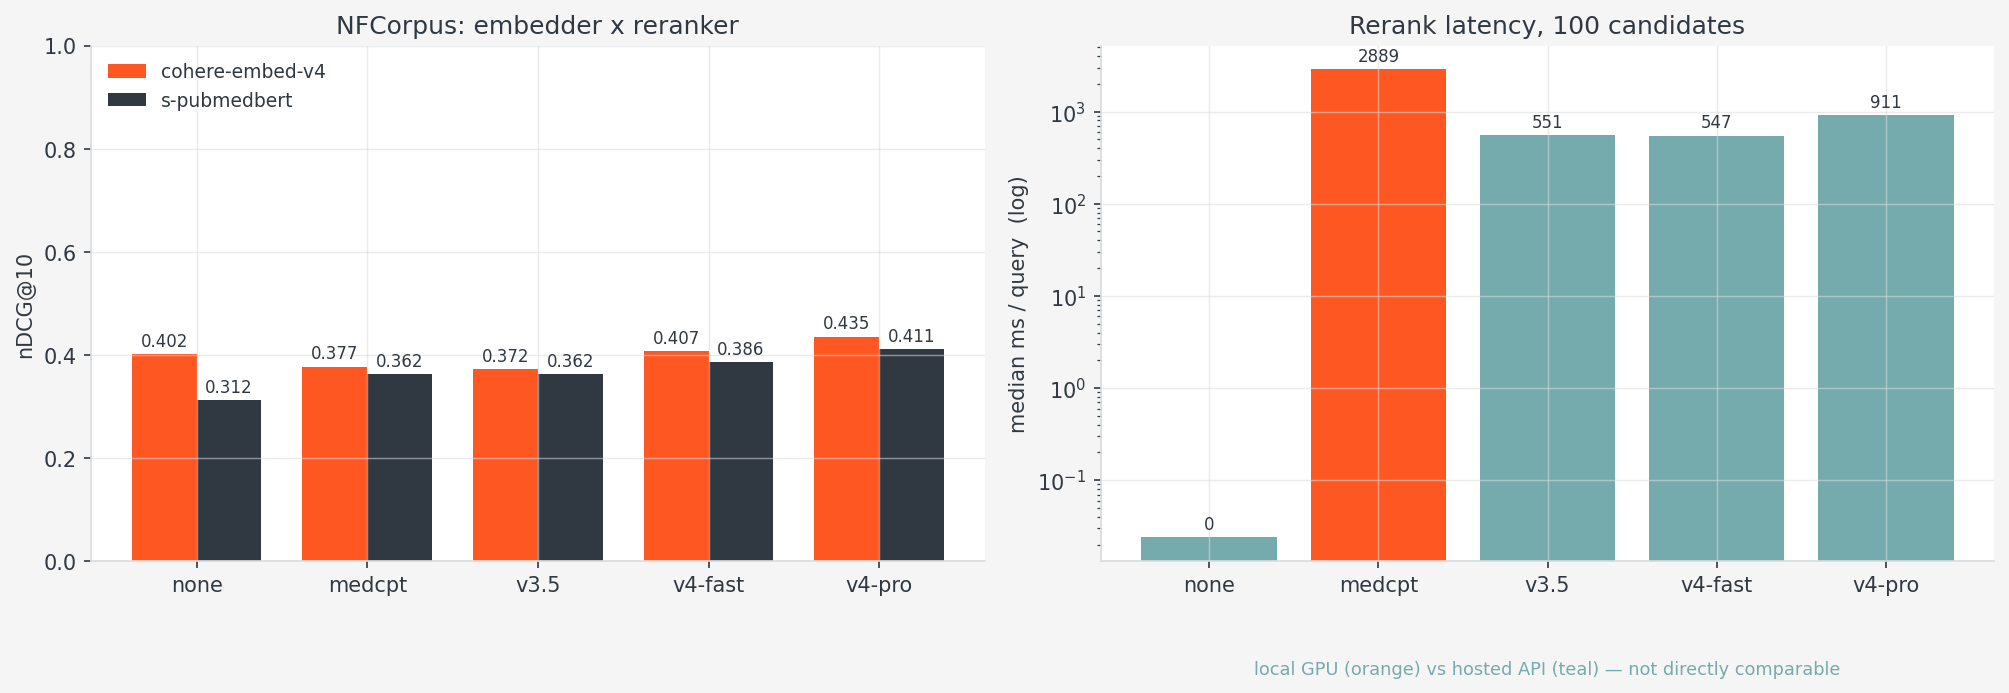

In [ ]:
import matplotlib.pyplot as plt

# ---- theme ----------------------------------------------------------------
_INK, _MUTED, _ACCENT = "#303841", "#76ABAE", "#FF5722"
_BG, _PANEL, _GRID    = "#F5F5F5", "#FFFFFF", "#D8DCDE"
_EMB_COLOR = {"s-pubmedbert": _INK, "cohere-embed-v4": _ACCENT}
_ORDER = ["none", "medcpt", "rerank-v3.5", "rerank-v4.0-fast", "rerank-v4.0-pro"]
_SHORT = {"none": "none", "medcpt": "medcpt", "rerank-v3.5": "v3.5",
          "rerank-v4.0-fast": "v4-fast", "rerank-v4.0-pro": "v4-pro"}

plt.rcParams.update({
    "figure.facecolor": _BG, "savefig.facecolor": _BG, "axes.facecolor": _PANEL,
    "axes.edgecolor": _GRID, "axes.labelcolor": _INK, "text.color": _INK,
    "xtick.color": _INK, "ytick.color": _INK, "grid.color": _GRID,
    "axes.grid": True, "grid.alpha": .55, "grid.linewidth": .7,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "legend.frameon": False,
})


def plot_grid(pivot, lat_by_arm, title, path):
    cols = [c for c in _ORDER if c in pivot.columns]
    pivot = pivot.reindex(columns=cols)
    lat_by_arm = lat_by_arm.reindex([c for c in _ORDER if c in lat_by_arm.index])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

    xs, w = np.arange(len(cols)), 0.38
    for i, emb in enumerate(pivot.index):
        b = ax1.bar(xs + i*w, pivot.loc[emb].values, w,
                    color=_EMB_COLOR.get(emb, _MUTED), label=emb)
        ax1.bar_label(b, fmt="%.3f", fontsize=8, padding=2, color=_INK)
    ax1.set_xticks(xs + w/2)
    ax1.set_xticklabels([_SHORT.get(c, c) for c in cols])
    ax1.set_ylim(0, max(1.0, pivot.values.max() * 1.18))
    ax1.set_ylabel("nDCG@10")
    ax1.set_title(title)
    ax1.legend(fontsize=9, loc="upper left")

    bars = ax2.bar([_SHORT.get(c, c) for c in lat_by_arm.index],
                   lat_by_arm.values.clip(min=0.02),
                   color=[_ACCENT if c == "medcpt" else _MUTED for c in lat_by_arm.index])
    ax2.bar_label(bars, fmt="%.0f", fontsize=8, padding=2, color=_INK)
    ax2.set_yscale("log")
    ax2.set_ylabel("median ms / query  (log)")
    ax2.set_title(f"Rerank latency, {TOP_N} candidates")
    ax2.text(0.5, -0.22, "local GPU (orange) vs hosted API (teal) — not directly comparable",
             transform=ax2.transAxes, ha="center", fontsize=8.5, color=_MUTED)

    plt.tight_layout()
    os.makedirs("results", exist_ok=True)
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

lat_nf_by_arm = df_nf.groupby("reranker")["ms"].median().reindex(list(RERANKERS))
plot_grid(pivot_nf, lat_nf_by_arm, "NFCorpus: embedder x reranker", "results/nfcorpus_grid.png")
df_nf.to_csv("results/nfcorpus_grid.csv", index=False)

---
# Part B - LUMEN

The real 77,649-passage corpus behind MediLink, now with pooled relevance judgments
covering 30 queries (`mohamedkhaledmk7/LUMEN-rag-data`, `qrels/`). This runs the exact
same grid and metrics as Part A.

**LUMEN's qrels are LLM-judged, not human.** Report these results separately from
NFCorpus's, never averaged.

In [ ]:
from huggingface_hub import hf_hub_download
from collections import defaultdict

REPO = "mohamedkhaledmk7/LUMEN-rag-data"
token = os.environ.get("HF_TOKEN") or None

chunks_path = hf_hub_download(REPO, "SpubMedBERT_chunks.json", repo_type="dataset", token=token)
embed_path  = hf_hub_download(REPO, "embeddings_spubmedbert.npy", repo_type="dataset", token=token)
qrels_path  = hf_hub_download(REPO, "qrels/lumen_qrels.tsv", repo_type="dataset", token=token)
lq_path     = hf_hub_download(REPO, "qrels/lumen_queries.jsonl", repo_type="dataset", token=token)

chunks = json.load(open(chunks_path))
E = np.load(embed_path).astype("float32")
E /= (np.linalg.norm(E, axis=1, keepdims=True) + 1e-12)
assert E.shape[0] == len(chunks), f"misaligned: {E.shape[0]} vs {len(chunks)}"

TEXT_KEYS = ("text", "chunk", "content", "passage")
def chunk_text(c):
    for k in TEXT_KEYS:
        if c.get(k): return str(c[k])
    return ""

doc_ids_lu   = [str(i) for i in range(len(chunks))]
doc_texts_lu = [chunk_text(c) for c in chunks]

queries_lu = {}
with open(lq_path) as f:
    for line in f:
        rec = json.loads(line)
        queries_lu[rec["_id"]] = rec["text"]

qrels_lu = defaultdict(dict)
with open(qrels_path) as f:
    next(f)
    for line in f:
        qid, did, score = line.rstrip("\n").split("\t")
        qrels_lu[qid][did] = int(score)

query_ids_lu = list(queries_lu.keys())
query_texts_lu = [queries_lu[q] for q in query_ids_lu]

print(f"LUMEN: {len(chunks):,} passages | {len(query_ids_lu)} queries | "
      f"{sum(len(v) for v in qrels_lu.values())} judgments")

SpubMedBERT_chunks.json: reconstructing file:   0%|          |  0.00B / 60.2MB            

SpubMedBERT_chunks.json: downloading bytes:           |  0.00B            

embeddings_spubmedbert.npy: reconstructing file:   0%|          |  0.00B /  239MB            

embeddings_spubmedbert.npy: downloading bytes:           |  0.00B            

lumen_qrels.tsv:   0%|          | 0.00/9.55k [00:00<?, ?B/s]

lumen_queries.jsonl:   0%|          | 0.00/3.44k [00:00<?, ?B/s]

LUMEN: 77,649 passages | 30 queries | 688 judgments


**Decide this before running the next cell.** Encoding all 77,649 LUMEN passages with
`embed-v4` costs roughly $1.80-2.00 (about 15M tokens) and takes 15-25 minutes. It is
by far the most expensive step in the notebook. Set the flag to `False` to skip it and
still get the full reranker comparison on the real corpus, using the published
S-PubMedBert embeddings only. The duo comparison needs both embedders, so it is skipped
too when this is off.

In [ ]:
RUN_COHERE_EMBED_ON_LUMEN = True    # False = skip the ~$2 / ~20 min corpus re-embed

EMBEDDERS_LU = dict(EMBEDDERS) if RUN_COHERE_EMBED_ON_LUMEN \
               else {"s-pubmedbert": EMBEDDERS["s-pubmedbert"]}

est = 0.0 if not RUN_COHERE_EMBED_ON_LUMEN else 15e6 / 1e6 * 0.12
print(f"LUMEN embedders: {list(EMBEDDERS_LU)}")
print(f"estimated embed cost for this choice: ${est:.2f}")

LUMEN embedders: ['s-pubmedbert', 'cohere-embed-v4']
estimated embed cost for this choice: $1.80


In [ ]:
CANDIDATES_BY_DS = {}
for name, fn in EMBEDDERS_LU.items():
    print(f"embedding LUMEN with {name} ...")
    if name == "s-pubmedbert":
        # corpus already embedded and published; only the queries need encoding
        from sentence_transformers import SentenceTransformer
        _m = SentenceTransformer(LOCAL_EMBEDDER)
        Q = _m.encode(query_texts_lu, normalize_embeddings=True, convert_to_numpy=True)
        D = E
    else:
        Q, D = fn(doc_texts_lu, query_texts_lu)
    CANDIDATES_BY_DS[name] = build_candidates(Q, D, doc_ids_lu, doc_texts_lu, query_ids_lu)
    print(f"  {name}: dim={D.shape[1]}, top-{TOP_N} built\n")

embedding LUMEN with s-pubmedbert ...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  s-pubmedbert: dim=768, top-100 built

embedding LUMEN with cohere-embed-v4 ...
  cohere-embed-v4: dim=1536, top-100 built



In [ ]:
df_lu, grid_lu, lat_lu = run_grid(CANDIDATES_BY_DS, queries_lu, qrels_lu, "lumen")

pivot_lu = df_lu.pivot(index="embedder", columns="reranker", values="nDCG@10")
print("\nLUMEN nDCG@10 grid\n")
print(pivot_lu.to_string())
df_lu

running [lumen] s-pubmedbert + none ...
  [lumen] s-pubmedbert + none: 25/30
  [lumen] s-pubmedbert + none: median       0 ms/query
running [lumen] s-pubmedbert + medcpt ...
  [lumen] s-pubmedbert + medcpt: median     802 ms/query
running [lumen] s-pubmedbert + rerank-v3.5 ...
  [lumen] s-pubmedbert + rerank-v3.5: median     404 ms/query
running [lumen] s-pubmedbert + rerank-v4.0-fast ...
  [lumen] s-pubmedbert + rerank-v4.0-fast: median     415 ms/query
running [lumen] s-pubmedbert + rerank-v4.0-pro ...
  [lumen] s-pubmedbert + rerank-v4.0-pro: median     646 ms/query
running [lumen] cohere-embed-v4 + none ...
  [lumen] cohere-embed-v4 + none: median       0 ms/query
running [lumen] cohere-embed-v4 + medcpt ...
  [lumen] cohere-embed-v4 + medcpt: median    1057 ms/query
running [lumen] cohere-embed-v4 + rerank-v3.5 ...
  [lumen] cohere-embed-v4 + rerank-v3.5: median     455 ms/query
running [lumen] cohere-embed-v4 + rerank-v4.0-fast ...
  [lumen] cohere-embed-v4 + rerank-v4.0-fast: me

,dataset,embedder,reranker,nDCG@10,MRR@10,R@1,R@3,R@5,R@10,ms
0,lumen,s-pubmedbert,none,0.6179,0.9722,0.0427,0.1235,0.1912,0.3932,0.0672
1,lumen,s-pubmedbert,medcpt,0.5889,0.9833,0.0429,0.1244,0.2014,0.3927,802.0019
2,lumen,s-pubmedbert,rerank-v3.5,0.7744,0.9733,0.0427,0.1264,0.2089,0.4241,403.9508
3,lumen,s-pubmedbert,rerank-v4.0-fast,0.8657,0.9722,0.0427,0.1281,0.2135,0.4321,414.8012
4,lumen,s-pubmedbert,rerank-v4.0-pro,0.9298,1.0000,0.0448,0.1343,0.2222,0.4381,646.0145
5,lumen,cohere-embed-v4,none,0.6183,0.9833,0.0427,0.1120,0.1723,0.3030,0.0471
6,lumen,cohere-embed-v4,medcpt,0.5479,0.9583,0.0416,0.1126,0.1876,0.3140,1056.5462
7,lumen,cohere-embed-v4,rerank-v3.5,0.6511,0.9250,0.0401,0.1083,0.1797,0.3325,454.9012
8,lumen,cohere-embed-v4,rerank-v4.0-fast,0.7102,0.9028,0.0389,0.1110,0.1719,0.3282,447.6060
9,lumen,cohere-embed-v4,rerank-v4.0-pro,0.7356,0.8944,0.0371,0.1136,0.1774,0.3263,666.5856


In [ ]:
if "cohere-embed-v4" in pivot_lu.index:
    lu_diff, lu_lo, lu_hi = report_duo(grid_lu, qrels_lu, query_ids_lu, "LUMEN")
else:
    print("Cohere embed-v4 arm skipped on LUMEN (RUN_COHERE_EMBED_ON_LUMEN=False); "
          "duo comparison needs both embedders.")

--- LUMEN ---
MediLink duo (S-PubMedBert + MedCPT)       mean nDCG@10 = 0.5889
Cohere duo (embed-v4 + rerank-v4.0-pro)    mean nDCG@10 = 0.7356

Cohere duo - MediLink duo: +0.1467  95% CI [+0.0716, +0.2256]  -> significant


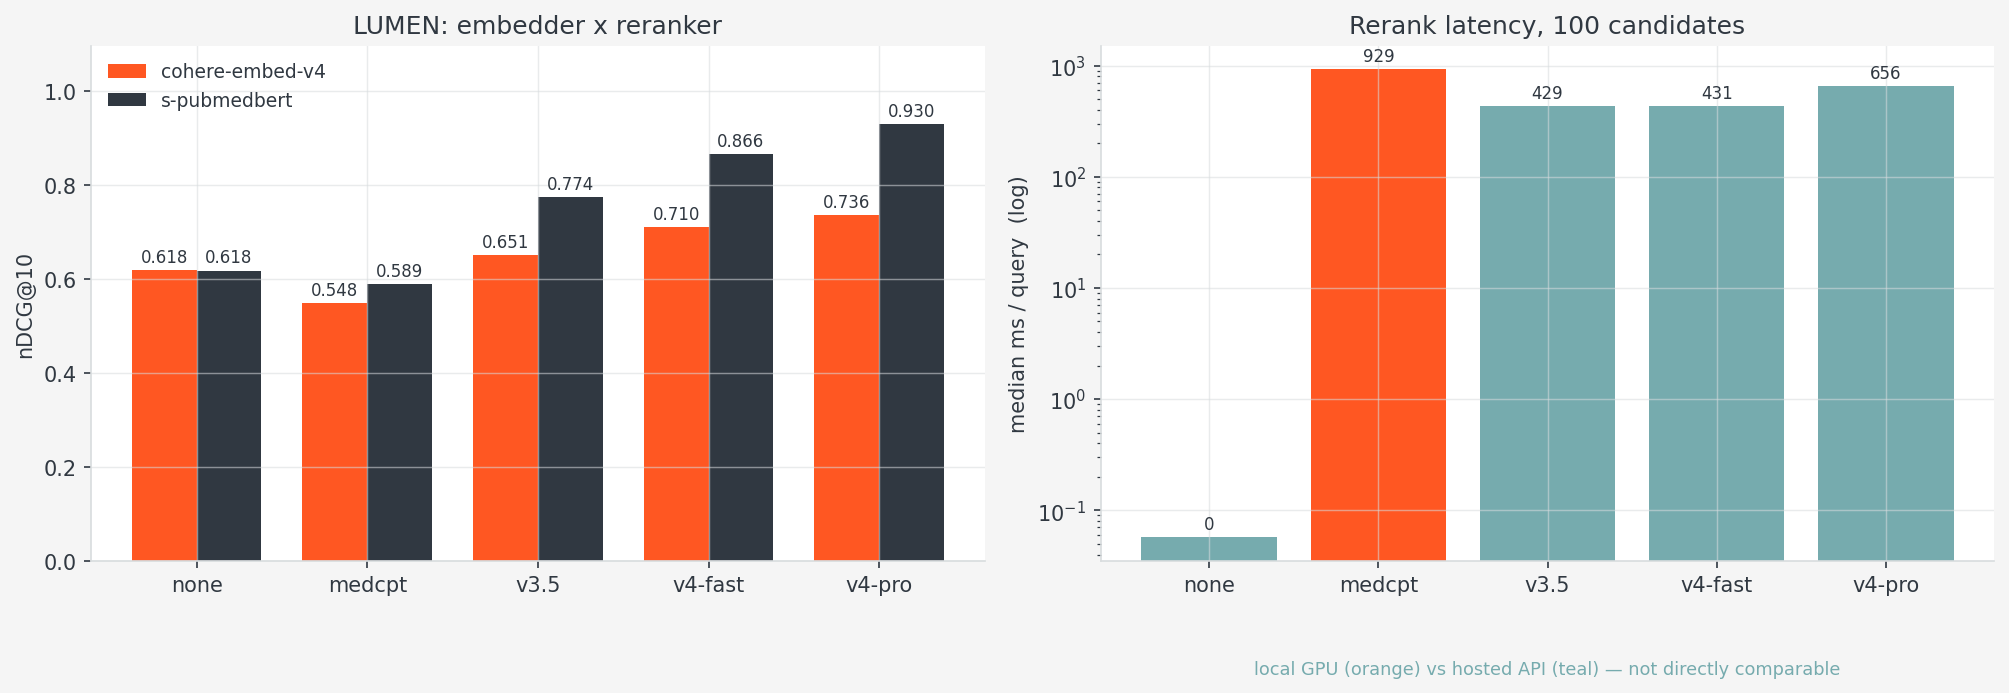

In [ ]:
lat_lu_by_arm = df_lu.groupby("reranker")["ms"].median().reindex(
    [r for r in RERANKERS if r in df_lu["reranker"].unique()])
plot_grid(pivot_lu, lat_lu_by_arm, "LUMEN: embedder x reranker", "results/lumen_grid.png")
df_lu.to_csv("results/lumen_grid.csv", index=False)

---
## Combined summary

Side by side, not averaged. NFCorpus has human qrels; LUMEN's are LLM-generated via
pooling (see the LUMEN dataset card for the method and self-consistency numbers).

In [ ]:
combined = pd.concat([df_nf, df_lu], ignore_index=True)
summary = combined.pivot_table(index=["dataset", "embedder"], columns="reranker",
                               values="nDCG@10")
print(summary.to_string())
combined.to_csv("results/combined_grid.csv", index=False)

reranker                  medcpt    none  rerank-v3.5  rerank-v4.0-fast  rerank-v4.0-pro
dataset  embedder                                                                       
lumen    cohere-embed-v4  0.5479  0.6183       0.6511            0.7102           0.7356
         s-pubmedbert     0.5889  0.6179       0.7744            0.8657           0.9298
nfcorpus cohere-embed-v4  0.3767  0.4016       0.3720            0.4074           0.4347
         s-pubmedbert     0.3619  0.3121       0.3617            0.3860           0.4110


In [ ]:
# ============================================================
# DIAGNOSTICS — run after Part B
# Needs in scope: qrels_lu, queries_lu, query_ids_lu, CANDIDATES_BY_DS,
#                 grid_lu, chunks, RERANKERS
# ============================================================

import numpy as np
from collections import Counter

print("=" * 74)
print("1.  IS TOP-1 TRIVIALLY EASY?  (why MRR is pinned near 1.0)")
print("=" * 74)

# For each query: is the FIRST dense-retrieved passage already relevant?
easy = 0
for qid in query_ids_lu:
    top1 = CANDIDATES_BY_DS["s-pubmedbert"][qid][0]["id"]
    if qrels_lu[qid].get(top1, 0) > 0:
        easy += 1
print(f"queries where plain dense retrieval already nails top-1: "
      f"{easy}/{len(query_ids_lu)} ({easy/len(query_ids_lu):.0%})")
print("-> if this is near 100%, MRR cannot discriminate between arms;")
print("   the metric is at a ceiling and nDCG/Recall carry the signal.\n")


print("=" * 74)
print("2.  HOW MUCH RELEVANT MATERIAL EXISTS PER QUERY?")
print("=" * 74)
sizes = [len(v) for v in qrels_lu.values()]
grades = Counter(s for v in qrels_lu.values() for s in v.values())
print(f"judged-relevant passages per query: min {min(sizes)}, "
      f"median {int(np.median(sizes))}, max {max(sizes)}")
print(f"grade counts: {dict(sorted(grades.items()))}")
print("-> Recall@10 is capped by these totals. With ~20 relevant passages")
print("   per query, Recall@10 can never exceed ~0.5 no matter how good")
print("   the ranking is. That explains the low R@10 numbers.\n")


print("=" * 74)
print("3.  WHERE DOES MedCPT LOSE TO NO-RERANK ON LUMEN?")
print("=" * 74)

import pytrec_eval
_ev = pytrec_eval.RelevanceEvaluator(
    {q: {d: int(s) for d, s in v.items()} for q, v in qrels_lu.items()},
    {"ndcg_cut.10"})

def per_q(res):
    sc = _ev.evaluate({q: {d: float(s) for d, s in v.items()} for q, v in res.items()})
    return {q: sc[q]["ndcg_cut_10"] for q in sc}

nq_none   = per_q(grid_lu[("s-pubmedbert", "none")])
nq_medcpt = per_q(grid_lu[("s-pubmedbert", "medcpt")])
nq_pro    = per_q(grid_lu[("s-pubmedbert", "rerank-v4.0-pro")])

deltas = sorted(((nq_medcpt[q] - nq_none[q], q) for q in nq_none))
hurt = [(d, q) for d, q in deltas if d < -0.01]
help_ = [(d, q) for d, q in deltas if d > 0.01]

print(f"MedCPT vs no-rerank:  hurts {len(hurt)} queries, "
      f"helps {len(help_)}, ~unchanged {len(deltas)-len(hurt)-len(help_)}")
print(f"\nworst 5 (MedCPT actively reordered good results downward):")
for d, q in deltas[:5]:
    print(f"  {d:+.3f}  {q}  {queries_lu[q][:66]}")
print(f"\nbest 5:")
for d, q in deltas[-5:]:
    print(f"  {d:+.3f}  {q}  {queries_lu[q][:66]}")

print(f"\nfor contrast, Cohere v4-pro vs no-rerank:")
pro_deltas = sorted(((nq_pro[q] - nq_none[q], q) for q in nq_none))
p_hurt = sum(1 for d, _ in pro_deltas if d < -0.01)
print(f"  hurts {p_hurt}, helps {sum(1 for d,_ in pro_deltas if d > 0.01)}")


print("\n" + "=" * 74)
print("4.  INSPECT THE WORST MedCPT CASE")
print("=" * 74)
worst_q = deltas[0][1]
print(f"QUERY: {queries_lu[worst_q]}")
print(f"  no-rerank nDCG@10 = {nq_none[worst_q]:.3f}")
print(f"  MedCPT    nDCG@10 = {nq_medcpt[worst_q]:.3f}\n")

def top_k_with_grades(arm, qid, k=5):
    ranked = sorted(grid_lu[arm][qid].items(), key=lambda kv: -kv[1])[:k]
    return [(did, qrels_lu[qid].get(did, 0)) for did, _ in ranked]

for arm, name in [(("s-pubmedbert", "none"), "no rerank"),
                  (("s-pubmedbert", "medcpt"), "MedCPT")]:
    print(f"[{name}] top-5  (passage_id, judged grade):")
    for did, g in top_k_with_grades(arm, worst_q):
        flag = "  <- relevant" if g > 0 else ""
        print(f"    {did:>7s}  grade {g}{flag}")
    print()

print("Read the two lists above. If MedCPT pushed grade-3 passages down and")
print("pulled grade-0 passages up, the underperformance is real. If the grades")
print("look arbitrary, suspect the qrels for this query instead.")


print("\n" + "=" * 74)
print("5.  POOLING BIAS CHECK")
print("=" * 74)
print("MedCPT contributed to the pool, so it cannot be penalised for")
print("surfacing unjudged passages. Confirming its top-10 are all judged:")
for arm, name in [(("s-pubmedbert", "medcpt"), "MedCPT"),
                  (("s-pubmedbert", "rerank-v4.0-pro"), "v4-pro")]:
    unjudged = 0
    total = 0
    for qid in query_ids_lu:
        ranked = sorted(grid_lu[arm][qid].items(), key=lambda kv: -kv[1])[:10]
        for did, _ in ranked:
            total += 1
            if did not in qrels_lu[qid]:
                unjudged += 1
    print(f"  {name:8s}: {unjudged}/{total} top-10 slots hold unjudged "
          f"passages ({unjudged/total:.0%})")
print("-> both arms pooled at depth 10, so both should be near 0%.")
print("   A large gap here would mean the comparison is biased.")

1.  IS TOP-1 TRIVIALLY EASY?  (why MRR is pinned near 1.0)
queries where plain dense retrieval already nails top-1: 29/30 (97%)
-> if this is near 100%, MRR cannot discriminate between arms;
   the metric is at a ceiling and nDCG/Recall carry the signal.

2.  HOW MUCH RELEVANT MATERIAL EXISTS PER QUERY?
judged-relevant passages per query: min 16, median 23, max 30
grade counts: {1: 203, 2: 220, 3: 265}
-> Recall@10 is capped by these totals. With ~20 relevant passages
   per query, Recall@10 can never exceed ~0.5 no matter how good
   the ranking is. That explains the low R@10 numbers.

3.  WHERE DOES MedCPT LOSE TO NO-RERANK ON LUMEN?
MedCPT vs no-rerank:  hurts 17 queries, helps 11, ~unchanged 2

worst 5 (MedCPT actively reordered good results downward):
  -0.335  LQ023  What molecular pathway drives basal cell carcinoma development?
  -0.321  LQ006  What are the main types of skin cancer and how do they differ?
  -0.238  LQ005  How does sentinel lymph node biopsy inform melanoma pro

## Findings

Ordered by how much weight each claim carries.

→ **MedCPT is the weakest reranker in the set.** It frequently

→ **The Cohere rerank tiers order consistently: v3.5 < v4.0-fast < v4.0-pro.** Same


→ **Reranker choice mattered more than embedder choice.** True on

→ **Which embedder wins depends on the dataset.** embed-v4 wins


## Recommendations

### For MediLink

→ **Reconsider MedCPT** It is the weakest reranker tested and the
slowest arm by a wide margin. Before replacing it, re-run the grid on hybrid candidates
with strengthened qrels, since both caveats bear directly on this decision. If the result
holds, rerank-v4.0-fast is the natural replacement: better quality, roughly a fifth of the
latency.

→ **Keep S-PubMedBert for now.** It wins on LUMEN against every matched reranker except
MedCPT, and LUMEN is the corpus the system actually serves. The embedding result is the
mixed one. Do not act on it without more evidence.

→ **Restore hybrid retrieval before deciding anything.** Candidate generation here is
dense-only, while production blends BM25 and dense at alpha = 0.60, varied per intent.
None of these numbers reproduce the retrieval setup actually in use.

### For the LUMEN qrels

→ **Judge the unjudged passages first.** MedCPT holds 11% of its top-10 slots with
passages absent from the qrels, against 2% for rerank-v4.0-pro. Closing that gap removes
the largest caveat on the strongest finding, and it is the smallest job on this list.

→ **Re-judge a sample with a different model family.** If MedCPT recovers under a
non-Claude judge, the LUMEN deficit is judge affinity. If it does not, it is real. This
separates two explanations currently tied in the limitations and costs about an hour.

→ **Add queries and deepen the pool.** Thirty queries give confidence intervals roughly
4x wider than NFCorpus's. Pooling at depth 20 instead of 10 also makes the qrels reusable
by systems that were not part of the pool, including any future reranker MediLink tests.

→ **Build the next query set from real traffic.** The current queries are corpus-derived,
so nearly all are answerable and absolute scores run high. Logged user queries would
include the questions the corpus cannot answer, which is where real retrieval failures
live.

### For general-purpose models in medical applications

→ **Measure before assuming either direction.** The specialist lost here; that is not a
general law. Domain models still hold advantages this benchmark does not test: rare-term
vocabulary, abbreviations and drug names, stability on text far from web distribution.

→ **Evaluate on the retrieval task actually being run.** These conclusions come from
dense-only retrieval over oncology literature with graded labels. A system doing hybrid
retrieval over clinical notes may rank the same models differently.

→ **Treat LLM-judged relevance carefully.** If an LLM grades relevance and an LLM-family
reranker is evaluated, the two may share a notion of relevance a domain specialist does
not, and the evaluation will reward that agreement. Anchor to human judgments where the
budget allows; treat LLM labels as a scaling aid, not a replacement.

→ **Do not read ranking quality as clinical safety.** nDCG measures whether relevant
passages rank highly. It says nothing about whether a passage is current,
guideline-concordant, or safe to act on.

## Conclusion

The reranking evidence is consistent and points one way. MedCPT finishes last across both
corpora and both embedders, the newest general-purpose tier finishes first, and reranker
choice moves results more than embedder choice does. The embedding evidence is mixed: the
domain model holds its own on the corpus it was built for, and two datasets are not enough
to say why.

##Current flagship general-purpose rerankers can outperform domain-specific models on the domain those models were built for. ##
Domain pretraining was a durable advantage when
general models were weaker. On this evidence it no longer reliably is, at least for
reranking. Reaching for a specialist model is now a decision to justify with measurement,
not a safe default.

# Reproducing and exploring the results

All figures are in `notebooks/04_analysis.ipynb`